Fichier pour tester la fonction distance pour résoudre le problème de 2018

In [6]:
from ift6758.features.simple_visualizations import games_list #, distance

import seaborn as sns
import matplotlib.pyplot as plt

In [36]:
from ift6758.features import json2tidy
from pathlib import Path
import pandas as pd
import numpy as np


def distance(dataframe) -> pd.DataFrame:
    """
    Function to add the column distance to the dataframe.
    Distance is the distance between the goal and the coordinates where the shot was taken

    Parameters:
        dataframe (pd.DataFrame) : Dataframe of the games

    Returns:
        pd.DataFrame
    """
    df = dataframe.copy()
    print("DF" + str(df))
    # team_defending: True is home_team, False is away_team
    # df["team_id"] contain "eventOwnerTeamId" which is the team associated with the action
    # df["team_id"] is the team that is trying to score
    df["team_defending"] = (df["team_id"] != df["homeTeam_id"])

    '''
    attacks_left = np.where(
        home_shoots,
        df_shots["homeTeamDefendingSide"] == "right",
        df_shots["homeTeamDefendingSide"] == "left"
    )

    # Flip the shots by 180° if they were taken from the left side of the pitch
    df_shots.loc[attacks_left, ["x_coord", "y_coord"]] *= -1'''

    #df["homeTeamDefendingSide"] =
    #df["side_defending"] = df["homeTeamDefendingSide"]
    print("DEFENDING SIDE:" + str(df["homeTeamDefendingSide"]))
    if df["homeTeamDefendingSide"].isnull().any():
        print("CHECK")
        df["side_defending"] = "left"
        #df.loc[df["period"]==1, "side_defending"] = "right"
        df.loc["side_defending"] = np.where(df["period"] % 2 == 0, "right", "left")
        """df["side_defending"] = df["side_defending"].where(df["period"]==1, "right")
        df["side_defending"] = df["side_defending"].where(df["period"]==2, "left")
        df["side_defending"] = df["side_defending"].where(df["period"]==3, "right")"""
        #print("THing")
        #print(df.where(df["period"]==3))
        #df.loc[df["period"]==2, "side_defending"] = "left" #df[np.where(df["period"]==2)
        #df.loc[df["period"]==3, "side_defending"] = "right"
        #df.loc[df["period"]==4, "side_defending"] = "left" # TODO
        #df["side_defending"][np.where(df["period"]==2)] = "left"
        #df["side_defending"][np.where(df["period"]==3)] = "right"
        print(df["side_defending"])
    else:
        df["side_defending"] = df["homeTeamDefendingSide"]
    # At this point side_defending is equal to homeTeamDefendingSide

    conditions = [df["side_defending"]=="right", df["side_defending"]=="left"]
    choices = ["left","right"]

    df["side_defending"] = np.where(df["team_defending"]==False, np.select(conditions,choices),df["side_defending"])

    # if right, goal_coor = (89,0)
    # else left, (-89,0)
    df["goalCoordX"] = np.where(df["side_defending"]=="right",89,-89)

    #calculate the distance between the x,y coordinates and the goal
    #the y coordinate for the goals is 0
    df["distance"] = np.sqrt((df["goalCoordX"]-df["x_coord"])**2 + df["y_coord"]**2)

    #Remove team_defending, side_defending, goalCoordX
    #Keep only the distance
    df = df.drop(
        columns = ["team_defending", "side_defending", "goalCoordX"]
    )

    return df

#print(distance(games_list(2018)))

def shot_or_goal(season):
    games = games_list(season)
    df = distance(games)
    return df[["distance","event_type"]]

In [37]:
sog2018 = shot_or_goal(2018)


DF          game_id  event_id    season situation_code  period   time  \
0      2018020001        10  20182019           1551       1  00:29   
1      2018020001        11  20182019           1551       1  00:49   
2      2018020001        12  20182019           1551       1  01:00   
3      2018020001        18  20182019           1551       1  03:54   
4      2018020001        20  20182019           1551       1  04:06   
...           ...       ...       ...            ...     ...    ...   
85934  2018030417       595  20182019           1551       3  15:22   
85935  2018030417       597  20182019           1551       3  15:51   
85936  2018030417       598  20182019           1551       3  15:55   
85937  2018030417       600  20182019           1560       3  16:50   
85938  2018030417       703  20182019           1560       3  17:50   

       shooter_id  scorer_id    event_type  x_coord  ...  \
0       8477476.0        NaN  shot-on-goal     78.0  ...   
1       8476853.0        

ValueError: cannot set a row with mismatched columns

C:\Users\willp\PycharmProjects\NHL-data-analysis\.venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\willp\PycharmProjects\NHL-data-analysis\.venv\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


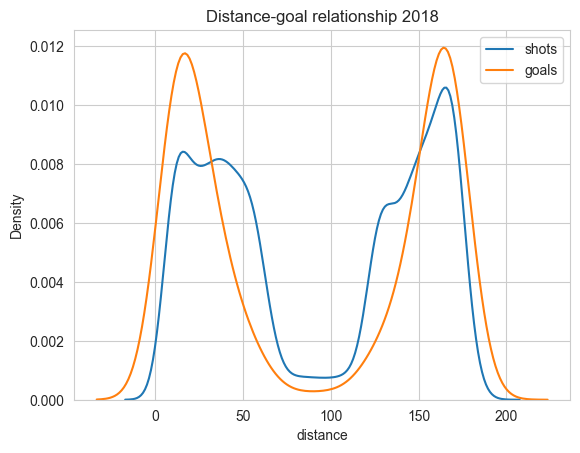

In [27]:
def og_figure2(season, shot_or_goal):
    """
    Function to draw kernel density estimate plot for the season specified

    Paramaters:
        season(int): Season to take de games from
    """

    shot = shot_or_goal[shot_or_goal["event_type"]!="goal"]
    goal = shot_or_goal[shot_or_goal["event_type"]=="goal"]

    sns.kdeplot(shot["distance"], label="shots")
    sns.kdeplot(goal["distance"], label="goals")

    plt.title("Distance-goal relationship " + str(season))
    plt.legend()

    # Save the figure for the blog post
    plt.savefig("testing_" + str(season) + ".png")
    plt.show()

og_figure2(2018, sog2018)